# DBSCAN pada Artikel Klarifikasi Hoaks Komdigi

Notebook ini menerapkan DBSCAN pada teks artikel dari `komdigi_hoaks.csv`. Teks judul, ringkasan, dan isi artikel diubah menjadi fitur TF-IDF; jarak cosine digunakan untuk mengelompokkan artikel dan mendeteksi noise.

Kolom `topics` hanya digunakan untuk evaluasi/interpretasi eksternal, bukan sebagai masukan DBSCAN. `topics` adalah label topik, bukan label klaim benar atau salah. DBSCAN dapat menghasilkan satu cluster atau semua noise bergantung pada `eps` dan `min_samples`.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import DBSCAN
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

# Dukung eksekusi dari root repository maupun folder notebook.
data_candidates = [
   Path("../../data/komdigi_hoaks.csv"),
]
data_path = next((path for path in data_candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("File komdigi_hoaks.csv tidak ditemukan.")

df = pd.read_csv(data_path)
print(f"Lokasi dataset: {data_path.resolve()}")
print("Ukuran awal:", df.shape)

# URL menjadi kunci untuk menghapus artikel berulang.
df = df.drop_duplicates(subset="url", keep="first").copy()
text_columns = ["title", "excerpt", "body_text"]
df[text_columns] = df[text_columns].fillna("").astype(str)
df["article_text"] = (
    df[text_columns]
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
df["topics"] = df["topics"].str.strip()

vectorizer = TfidfVectorizer(
    max_features=5000,
    min_df=2,
    ngram_range=(1, 2),
    sublinear_tf=True,
)
X = vectorizer.fit_transform(df["article_text"])
print("Artikel setelah deduplikasi:", len(df))
print("Ukuran matriks TF-IDF:", X.shape)
display(df[["title", "topics", "article_text"]].head())

Lokasi dataset: D:\Kuliah\Kelas\Semester 5\Pembelajaran Mesin\TUGAS\PRAKTIKUM\data\komdigi_hoaks.csv
Ukuran awal: (4176, 13)
Artikel setelah deduplikasi: 4162
Ukuran matriks TF-IDF: (4162, 5000)


,title,topics,article_text
0,[HOAKS] Tautan Pencairan BSU September 2026 Se...,Hoaks,[HOAKS] Tautan Pencairan BSU September 2026 Se...
1,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...,Hoaks,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...
2,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...,Hoaks,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...
3,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...,Hoaks,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...
4,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...,Hoaks,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...


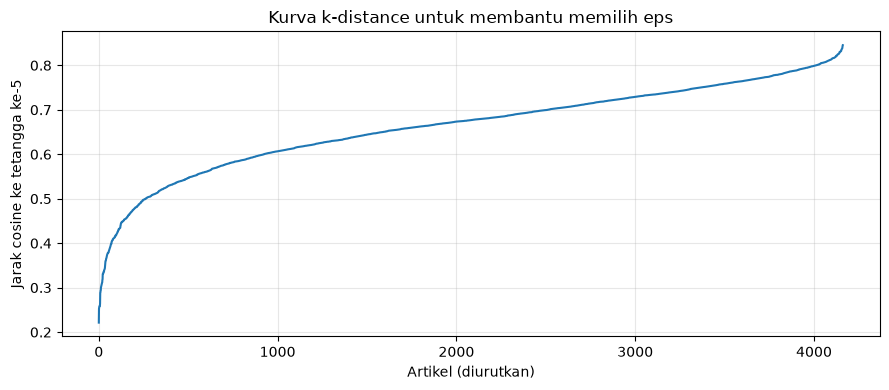

Kuantil jarak:


,distance
0.10,0.533142
0.25,0.609635
0.50,0.676754
0.75,0.735168
0.90,0.774114


In [2]:
# Plot k-distance membantu memilih eps. Jarak ke tetangga ke-5 digunakan sebagai panduan.
min_samples = 5
neighbors = NearestNeighbors(n_neighbors=min_samples, metric="cosine", n_jobs=-1)
neighbors.fit(X)
distances, _ = neighbors.kneighbors(X)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 4))
plt.plot(np.arange(len(k_distances)), k_distances)
plt.xlabel("Artikel (diurutkan)")
plt.ylabel(f"Jarak cosine ke tetangga ke-{min_samples}")
plt.title("Kurva k-distance untuk membantu memilih eps")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("Kuantil jarak:")
display(pd.Series(k_distances).quantile([0.1, 0.25, 0.5, 0.75, 0.9]).rename("distance").to_frame())

In [3]:
# Jalankan DBSCAN pada fitur TF-IDF yang sparse dengan jarak cosine.
eps = 0.7
dbscan = DBSCAN(eps=eps, min_samples=min_samples, metric="cosine", n_jobs=-1)
labels = dbscan.fit_predict(X)
df["cluster"] = labels

cluster_ids = set(labels)
n_clusters = len(cluster_ids - {-1})
noise_count = int(np.sum(labels == -1))
print(f"eps={eps}; min_samples={min_samples}")
print("Jumlah cluster (di luar noise):", n_clusters)
print("Jumlah artikel noise:", noise_count, f"({noise_count / len(df):.1%})")
print("Jumlah artikel per label (-1 menandakan noise):")
display(df["cluster"].value_counts().sort_index().rename("jumlah artikel").to_frame())

eps=0.7; min_samples=5
Jumlah cluster (di luar noise): 19
Jumlah artikel noise: 967 (23.2%)
Jumlah artikel per label (-1 menandakan noise):


,jumlah artikel
cluster,
-1,967
0,3075
1,11
2,8
3,5
4,4
5,6
6,21
7,5


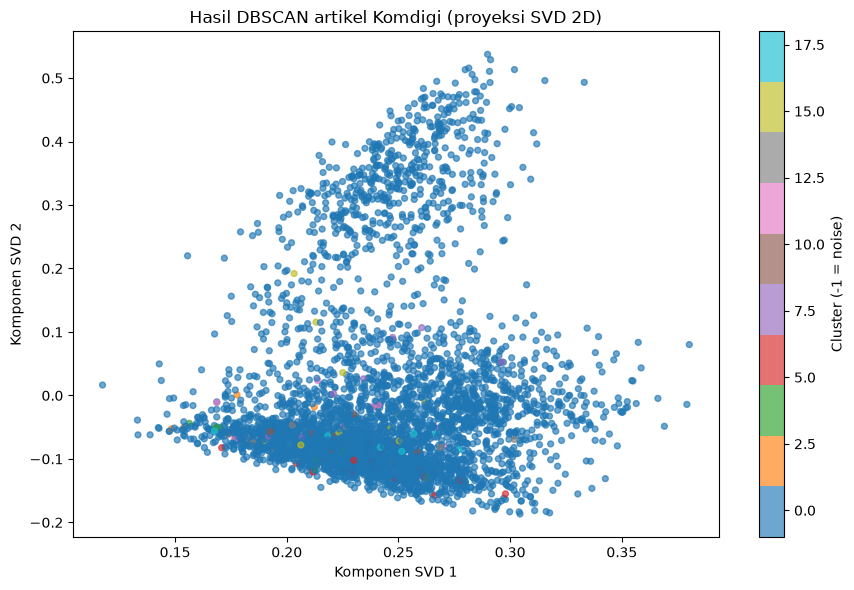

Variansi yang dijelaskan SVD 2D: 0.0247


In [4]:
# Visualisasi proyeksi SVD 2D; clustering tetap dihitung pada seluruh fitur TF-IDF.
svd_2d = TruncatedSVD(n_components=2, random_state=42)
X_2d = svd_2d.fit_transform(X)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_2d[:, 0], X_2d[:, 1], c=labels, cmap="tab10", s=18, alpha=0.65
)
plt.xlabel("Komponen SVD 1")
plt.ylabel("Komponen SVD 2")
plt.title("Hasil DBSCAN artikel Komdigi (proyeksi SVD 2D)")
plt.colorbar(scatter, label="Cluster (-1 = noise)")
plt.tight_layout()
plt.show()
print("Variansi yang dijelaskan SVD 2D:", round(svd_2d.explained_variance_ratio_.sum(), 4))

In [8]:
# Evaluasi eksternal membandingkan hasil cluster dengan topics, bukan menganggap topics sebagai fitur.
ari = adjusted_rand_score(df["topics"], labels)
nmi = normalized_mutual_info_score(df["topics"], labels)
print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")
print("Tabulasi cluster terhadap topics (noise tetap sebagai label -1):")
display(pd.crosstab(df["cluster"], df["topics"]))

# Silhouette hanya dihitung pada artikel non-noise dan bila ada minimal dua cluster.
non_noise = labels != -1
non_noise_labels = labels[non_noise]
if len(np.unique(non_noise_labels)) >= 2:
    sample_size = min(1000, int(non_noise.sum()))
    silhouette = silhouette_score(
        X[non_noise], non_noise_labels,
        metric="cosine", sample_size=sample_size, random_state=42,
    )
    print(f"Silhouette cosine pada data non-noise (sampel <= {sample_size}): {silhouette:.4f}")
else:
    print("Silhouette tidak dihitung: diperlukan minimal dua cluster non-noise.")

Adjusted Rand Index (ARI): -0.0594
Normalized Mutual Information (NMI): 0.0341
Tabulasi cluster terhadap topics (noise tetap sebagai label -1):


topics,Hoaks,Kesehatan,Masyarakat Digital,Pejabat Publik,Penipuan,Program/Kebijakan
cluster,,,,,,
-1,878,25,22,3,19,20
0,2533,29,78,132,266,37
1,11,0,0,0,0,0
2,8,0,0,0,0,0
3,5,0,0,0,0,0
4,4,0,0,0,0,0
5,6,0,0,0,0,0
6,21,0,0,0,0,0
7,5,0,0,0,0,0


Silhouette cosine pada data non-noise (sampel <= 1000): -0.0286


In [7]:
# Interpretasi tiap cluster melalui istilah dengan frekuensi dokumen tertinggi.
feature_names = vectorizer.get_feature_names_out()
for cluster_id in sorted(set(labels) - {-1}):
    cluster_rows = labels == cluster_id
    term_weights = np.asarray(X[cluster_rows].sum(axis=0)).ravel()
    top_indices = np.argsort(term_weights)[-12:][::-1]
    top_terms = feature_names[top_indices]
    print(f"Cluster {cluster_id} ({cluster_rows.sum()} artikel): {', '.join(top_terms)}")

if noise_count:
    print(f"\nContoh artikel noise ({noise_count} artikel):")
    display(df.loc[labels == -1, ["title", "topics"]].head(10))

Cluster 0 (3075 artikel): yang, tersebut, akun, dan, hoaks, tidak, di, com, id, dari, mengatasnamakan, https
Cluster 1 (11 artikel): karhutla, kebakaran hutan, kebakaran, hutan, kalimantan, lahan, penanganan, malaysia, 2026, asap, air, di
Cluster 2 (8 artikel): bem, bem ui, ui, mahasiswa, aksi, demonstrasi, universitas, demo, eksekutif, psi, agustus 2026, indonesia
Cluster 3 (5 artikel): paus fransiskus, paus, fransiskus, jenazah, patung, emas, al, video, april 2025, pembuatan, youtube, hasil
Cluster 4 (4 artikel): febrie, agung, pidana, dugaan korupsi, uang, jaksa agung, korupsi, jaksa, muda, dugaan, tindak pidana, tindak
Cluster 5 (6 artikel): selat, selat malaka, malaka, di selat, kapal, melintas, internasional, amerika, tarif, singapura, memungut, lintas
Cluster 6 (21 artikel): israel, netanyahu, gaza, di gaza, palestina, tni, perdana menteri, indonesia, video, perdana, militer, pasukan
Cluster 7 (5 artikel): tol, jalan tol, jalan, di jalan, kendaraan, menuju, harimau, video, di, m

,title,topics
2,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...,Hoaks
6,[HOAKS] Kemendikbud Bakal Melarang Guru Punya ...,Hoaks
15,[HOAKS] Pemadaman Internet Nasional Selama 3 ...,Program/Kebijakan
18,[HOAKS] Foto Pesawat Jatuh di Area Persawahan ...,Hoaks
34,[HOAKS] Rekaman Video Tenggelamnya KMP Virgo 8...,Hoaks
37,[HOAKS] Video Permohonan Dua Guru Luwu Utara y...,Hoaks
41,[HOAKS] Video Dapur SPPG di Kabupaten Lombok T...,Hoaks
51,[HOAKS] Agen Perlinsos Mendapatkan Insentif,Hoaks
52,[HOAKS] Vaksin mFLUSIVA Dinamai Berdasarkan De...,Hoaks
53,[HOAKS] Cek Kesehatan Gratis Itu Agenda Plande...,Hoaks


In [6]:
# Sensitivitas DBSCAN terhadap eps; bandingkan jumlah cluster dan noise.
eps_values = [0.55, 0.6, 0.65, 0.7, 0.75, 0.8]
sensitivity_rows = []
for eps_value in eps_values:
    candidate_labels = DBSCAN(
        eps=eps_value,
        min_samples=min_samples,
        metric="cosine",
        n_jobs=-1,
    ).fit_predict(X)
    candidate_clusters = set(candidate_labels) - {-1}
    cluster_sizes = pd.Series(candidate_labels)[candidate_labels != -1].value_counts()
    sensitivity_rows.append({
        "eps": eps_value,
        "jumlah_cluster": len(candidate_clusters),
        "noise_persen": round(np.mean(candidate_labels == -1) * 100, 2),
        "ukuran_cluster_terbesar": int(cluster_sizes.max()) if not cluster_sizes.empty else 0,
    })

display(pd.DataFrame(sensitivity_rows))

,eps,jumlah_cluster,noise_persen,ukuran_cluster_terbesar
0,0.55,49,79.19,313
1,0.60,62,63.53,442
2,0.65,49,44.09,1819
3,0.70,19,23.23,3075
4,0.75,3,7.42,3846
5,0.80,1,0.53,4140
